## Лабораторная работа №2
### Факторный анализ. Метод главных компонент
##### Задачи исследования

1. Применить факторный анализ (метод главных компонет) к совокупности анализируемых данных. Проанализировать целесообразность использования данного метода анализа на основе специальных критериев и тестовых статистик.
2. На основании результатов факторного анализа определить наиболее значимые коэффициенты, сохраняющие наибольший процент дисперсии исходных показателей.
3. Рассчитать интегральный показатель кредитоспособности как взвешенную сумму полученных главных компонент. В качестве весов использовать соответствующие величины процентов объясненной дисперсии.
---

In [25]:
import pandas as pd
import numpy as np
import pyreadstat
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity, calculate_kmo

data_path = '../Lab1/data_prepared.sav'
data, meta = pyreadstat.read_sav(data_path)
data = data.drop(columns = ['Cреднеспис.числ.работн', 'Year', 'k8', 'k4_new'])

display(data.head())

,k1,k2,k3,k4,k5,k6,k7,k9,k10,k11,k12,k13,k14,k15,k16,k17,k18,k19,k20
0,-0.844835,-0.462730,-0.072648,-0.598994,-0.751148,-0.331432,1.278778,-0.146335,-1.082426,-0.557283,-0.577876,-0.835996,-0.825805,-1.047613,-0.607049,2.602140,0.211227,-0.243578,-0.328480
1,0.157523,0.455945,0.365043,1.203309,-1.370943,-0.037174,-0.855084,1.748623,-1.070642,-0.097657,-0.465682,-0.753145,0.213520,0.029907,-0.432844,2.602140,0.779055,-0.182741,-0.426828
2,-1.393485,-0.716524,-1.161337,-1.910963,-0.565866,1.487737,2.129474,-0.236418,-1.309145,-1.650874,-0.297390,-1.718144,-1.442924,-0.751906,2.389905,-0.086135,-2.270520,-0.820572,-0.699316
3,2.332474,2.562626,2.294498,1.779887,-1.535617,-1.045480,-0.795666,2.233061,0.262642,-0.213310,0.041887,1.810148,1.973667,1.823270,-0.837995,-0.153880,1.582677,2.020363,2.113090
4,-0.036668,-0.698900,0.303591,0.981855,-1.117287,1.929763,1.764138,0.982473,-0.872526,-1.331145,-0.818413,-1.138972,-0.627855,-1.157741,-0.828347,-0.460696,0.038988,-0.623905,-0.573538


Был исключен коэффицент k8, так как из предыдущей работы мы знаем, что он имеете сильную отрицательную корреляцию с k5. И был исключен коэффицент k4_new, так как есть столбец k4 без пропусков

Для оценки целесообразности применения факторного анализа для конкретной выборки данных используются специальные критерии и тестовые статистики, которые позволяют исследовать требуемые свойства выборочной корреляционной матрицы. В рамках проводимого анализа используются: критерий сферичности Бартлетта и статистика Кайзера−Мейера−Олкина (КМО).

### Критерий сферичности Бартлетта

$$
\chi^2 = -\left(n - 1 - \frac{2p + 5}{6}\right) \cdot \ln |R|
$$

Где:
- $\chi^2$ — вычисляемое значение статистики Хи-квадрат.
- $n$ — объем выборки (количество наблюдений/строк в данных).
- $p$ — количество исходных переменных (столбцов).
- $|R|$ — определитель (детерминант) корреляционной матрицы исходных данных.

Нулевая гипотеза $H_0$: корреляционная матрица является единичной.

---

### Статистика Кайзера–Мейера–Олкина

$$
KMO = \frac{\sum_{i \neq j} r_{ij}^2}{\sum_{i \neq j} r_{ij}^2 + \sum_{i \neq j} a_{ij}^2}
$$

Где:
- $r_{ij}$ — парный (обычный) коэффициент корреляции Пирсона между переменной $i$ и переменной $j$.
- $a_{ij}$ — коэффициент частной корреляции между переменной $i$ и переменной $j$ при исключении влияния всех остальных переменных модели.

Частным (условным) коэффициентом корреляции непрерывных случайных величин $X$ и $Y$ при условии, что значение $Z$ фиксировано (влияние $Z$ «вычтено»), называется характеристика:

$$
\rho_{X,Y|Z} = \frac{\rho_{X,Y} - \rho_{X,Z}\rho_{Y,Z}}{\sqrt{(1 - \rho_{X,Z}^2)(1 - \rho_{Y,Z}^2)}} \in [-1, 1]
$$

Где:
- $\rho_{X,Y}$, $\rho_{X,Z}$, $\rho_{Y,Z}$ — обычные парные коэффициенты корреляции Пирсона между соответствующими парами переменных.

In [11]:
chi_square_value, p_value = calculate_bartlett_sphericity(data)
kmo_all, kmo_model = calculate_kmo(data)

print(f"Статистика Хи-квадрат (Бартлетт): {chi_square_value:.2f}")
print(f"p-value (Бартлетт): {p_value:.5f}")
print(f"Общий индекс KMO: {kmo_model:.3f}")

Статистика Хи-квадрат (Бартлетт): 41436.56
p-value (Бартлетт): 0.00000
Общий индекс KMO: 0.733


То что матрица является единичной отклоняется в соответствии с критерием Бартлетта. А значение статистики КМО 0.733 говорит о приемлем качестве выборки для применения факторного анализа

In [24]:
pca = PCA()
pca.fit(data)

variance_df = pd.DataFrame({
    'Собственное значение': pca.explained_variance_,
    'Доля дисперсии': pca.explained_variance_ratio_ * 100,
    'Накопленная дисперсия': np.cumsum(pca.explained_variance_ratio_) * 100
})

variance_df.index = [f'PC{i+1}' for i in range(len(variance_df))]

display(variance_df)

,Собственное значение,Доля дисперсии,Накопленная дисперсия
PC1,6.033273,31.742286,31.742286
PC2,2.856207,15.027091,46.769376
PC3,1.928004,10.143622,56.912998
PC4,1.586778,8.348367,65.261365
PC5,1.211399,6.373417,71.634782
PC6,1.101557,5.795518,77.430300
PC7,0.832084,4.377765,81.808065
PC8,0.691999,3.640749,85.448814
PC9,0.564847,2.971774,88.420588
PC10,0.537550,2.828162,91.248750


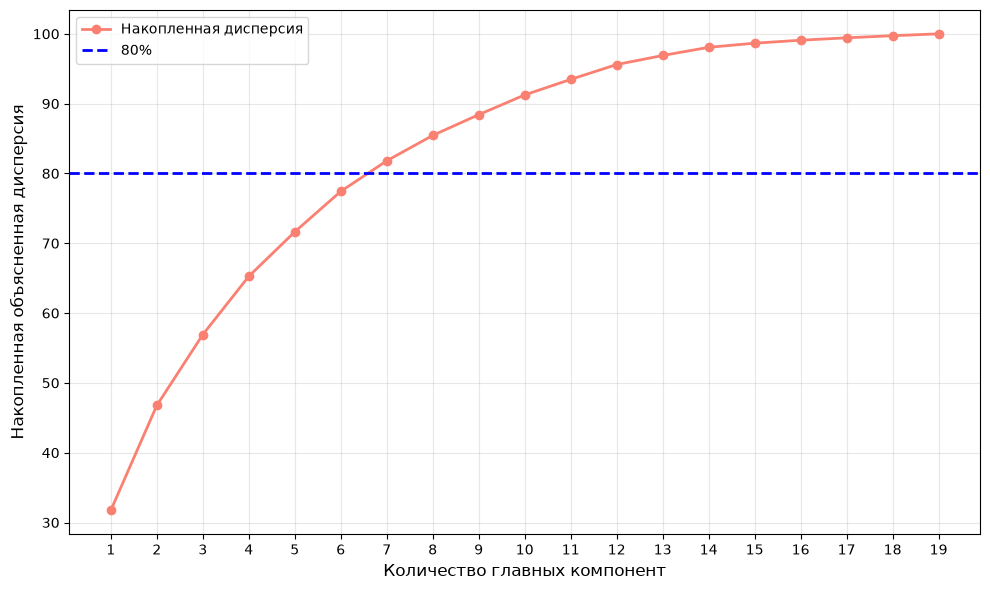

In [21]:
import matplotlib.pyplot as plt
import numpy as np

cumulative_variance = np.cumsum(pca.explained_variance_ratio_) * 100

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(cumulative_variance) + 1), 
         cumulative_variance, marker = 'o', linestyle = '-', color = 'salmon', linewidth = 2, label = 'Накопленная дисперсия')
plt.axhline(y = 80, color = 'blue', linestyle = '--', linewidth = 2, label = '80%')

plt.xlabel('Количество главных компонент', fontsize = 12)
plt.ylabel('Накопленная объясненная дисперсия', fontsize = 12)
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

По правилу кайзера стоит брать компоеннты у которых собственные значения больше 1. Это первые 6 компнент. Но также можно воспользоваться и правилом локтя и заметить что график становится пологим чуть позже чем после 6 компоненты. Поэтому было принято решение взять 7 компонент


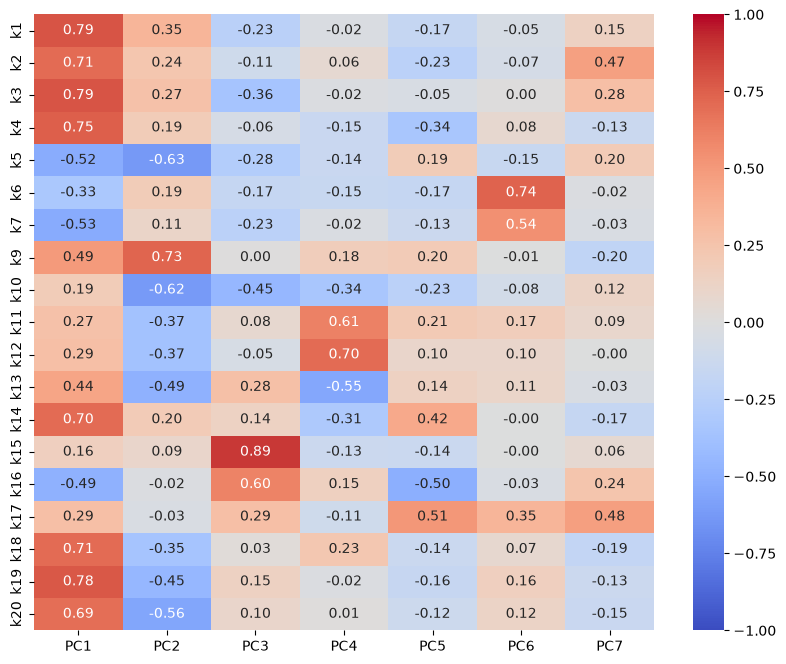

In [ ]:
factor_weights = pca.components_.T * np.sqrt(pca.explained_variance_)
pca_res = pd.DataFrame(factor_weights, columns = [f"PC{i+1}" for i in range(pca.n_components_)], index = data.columns)

plt.figure(figsize = (10, 8))
sns.heatmap(pca_res.iloc[:, :7], annot = True, fmt = '.2f', vmin = -1, vmax = 1, cmap = 'coolwarm')
plt.show()

- Можно заметить, что PC1 содержит в себе информацию о коэффицентах k1 - k4, k14, k18- k20. Также есть и значительная обратная связь с коэффицентами k5, k7, k16
- В PC2 выделяется k9, но и много обратных связей k10, k13, k20.
- В PC3 очень сильная связть с k15

Но также мы моожем заметить, что многие коэффиценты размазались по нескольким факторам. Поэтому в нащем случае обычный PCA недостаточно хорош